**Package**

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
import PIL
import PIL.Image
import tensorflow as tf

In [2]:
print(tf.__version__)

2.21.0


**Load data**

The experiment is conducted using the real-time wafer map dataset WM-811K. The data is available on Kaggle: https://www.kaggle.com/qingyi/wm811k-wafer-map. This is a public dataset from the Multimedia Information Retrieval (MIR) lab (http://mirlab.org/dataset/public/).

This dataset contains 811,457 wafer maps collected from 46,393 lots in real-world fabrication. The dataset includes nine regular wafer map failure pattern types: Center, Donut, Local, Edge-Local, Edge-Ring, Scratch, Random, Near-Full, and None.


---


Thí nghiệm được thực hiện bằng cách sử dụng bộ dữ liệu bản đồ wafer thời gian thực WM-811K. Dữ liệu có sẵn trên Kaggle: https://www.kaggle.com/qingyi/wm811k-wafer-map. Đây là bộ dữ liệu công khai từ phòng thí nghiệm Truy xuất Thông tin Đa phương tiện (MIR) (http://mirlab.org/dataset/public/).

Bộ dữ liệu này chứa 811.457 bản đồ wafer được thu thập từ 46.393 lô trong quá trình sản xuất thực tế. Bộ dữ liệu bao gồm chín loại mẫu lỗi bản đồ wafer thông thường: Trung tâm, Vòng tròn, Cục bộ, Cục bộ ở cạnh, Vòng ở cạnh, Vết xước, Ngẫu nhiên, Gần đầy và Không có.

In [7]:
# Data
import sys
import pickle
import pandas.core.indexes

# Khắc phục tính tương thích cho pickle tạo từ Pandas / Python cũ
sys.modules['pandas.indexes'] = pandas.core.indexes

# Đọc dữ liệu bằng pickle với encoding='latin1'
with open('../data/wafers.pkl', 'rb') as f:
    df = pickle.load(f, encoding='latin1')

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 811457 entries, 0 to 811456
Data columns (total 6 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   waferMap        811457 non-null  object 
 1   dieSize         811457 non-null  float64
 2   lotName         811457 non-null  object 
 3   waferIndex      811457 non-null  float64
 4   trianTestLabel  811457 non-null  object 
 5   failureType     811457 non-null  object 
dtypes: float64(2), object(4)
memory usage: 37.1+ MB


The dataset contains additional information on the wafer maps such as wafer die size, lot name and wafer index (25 wafers per lot).

The training/test sets have already been split by domain experts in this dataset, but these labels will be ignored.


---
Tập dữ liệu này chứa thông tin bổ sung về bản đồ wafer như kích thước chip wafer, tên lô và chỉ số wafer (25 wafer mỗi lô).

Các tập dữ liệu huấn luyện/kiểm tra đã được các chuyên gia trong lĩnh vực này phân chia, nhưng các nhãn này sẽ bị bỏ qua.


In [8]:
df.head(26)

,waferMap,dieSize,lotName,waferIndex,trianTestLabel,failureType
0,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...",1683.0,lot1,1.0,[[Training]],[[none]]
1,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...",1683.0,lot1,2.0,[[Training]],[[none]]
2,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...",1683.0,lot1,3.0,[[Training]],[[none]]
3,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...",1683.0,lot1,4.0,[[Training]],[[none]]
4,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...",1683.0,lot1,5.0,[[Training]],[[none]]
5,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...",1683.0,lot1,6.0,[[Training]],[[none]]
6,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...",1683.0,lot1,7.0,[[Training]],[[none]]
7,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...",1683.0,lot1,8.0,[[Training]],[[none]]
8,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...",1683.0,lot1,9.0,[[Training]],[[none]]
9,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...",1683.0,lot1,10.0,[[Training]],[[none]]


The waferMap column contains the wafer bin map, pixel by pixel. For simplicity, each die on the WBM is considered failed if it fails for at least one test, and otherwise it is considered functional. If a die on a wafer fails, it is marked as 2 or it is marked 1 if it passes. Therefore, each pixels has a categorical variable that expresses

0 : not wafer\
1 : normal\
2 : faulty\
The waferIndex column indicates the index of the wafer in a 25-wafer lot. Because of this, we will change the type of "waferIndex" to interger. Also changing the column "trianTestLabel" to the correct spelling.


---
Cột waferMap chứa bản đồ vị trí wafer, từng pixel một. Để đơn giản, mỗi chip trên WBM được coi là lỗi nếu nó không vượt qua ít nhất một bài kiểm tra, và ngược lại nó được coi là hoạt động bình thường. Nếu một chip trên wafer bị lỗi, nó được đánh dấu là 2, hoặc được đánh dấu là 1 nếu nó vượt qua. Do đó, mỗi pixel có một biến phân loại thể hiện:

0 : không phải wafer\
1 : bình thường\
2 : bị lỗi\
Cột waferIndex cho biết chỉ số của wafer trong lô 25 wafer. Vì lý do này, chúng ta sẽ thay đổi kiểu dữ liệu của "waferIndex" thành số nguyên. Đồng thời thay đổi tên cột "trianTestLabel" thành chính tả chính xác.


In [9]:
df.rename(columns={'trianTestLabel':'trainTestLabel'}, inplace=True)
df.tail()

,waferMap,dieSize,lotName,waferIndex,trainTestLabel,failureType
811452,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 2, 1, 1,...",600.0,lot47542,23.0,[[Test]],[[Edge-Ring]]
811453,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 2, 2, 1, 1,...",600.0,lot47542,24.0,[[Test]],[[Edge-Loc]]
811454,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 2, 1, 1,...",600.0,lot47542,25.0,[[Test]],[[Edge-Ring]]
811455,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1,...",600.0,lot47543,1.0,[],[]
811456,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 2, 1, 1,...",600.0,lot47543,2.0,[],[]


From the "lotName" column, the dataset is collected from 47,543 lots. However, 47,543 lots x 25 wafer/lot = 1,157,325 wafer maps, which is greater than 811,457 wafer maps. I suspect that not all lots have 15 wafers; the last lot only has 2.

Let's see what happened.


---

Từ cột "lotName", tập dữ liệu được thu thập từ 47.543 lô. Tuy nhiên, 47.543 lô x 25 wafer/lô = 1.157.325 bản đồ wafer, lớn hơn 811.457 bản đồ wafer. Tôi nghi ngờ rằng không phải tất cả các lô đều có 15 wafer; lô cuối cùng chỉ có 2 wafer.

Hãy xem điều gì đã xảy ra.

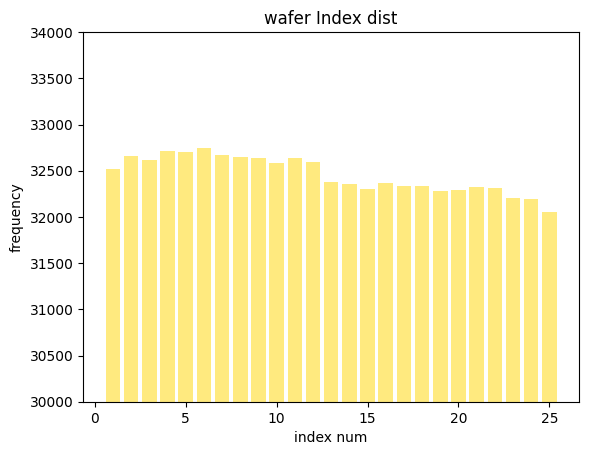

In [10]:
# 1. The distribution of lot_idx and num_wafer
lot_index = np.unique(df.waferIndex, return_counts=True)
plt.bar(lot_index[0], lot_index[1], color='gold', align='center', alpha=0.5)
plt.title("wafer Index dist")
plt.xlabel("index num")
plt.ylabel("frequency")
plt.ylim(30000, 34000)
plt.show()

The figure shows that not all lots have perfect 25 wafer maps. Fortunately, we do not need wafer index feature in our classification, so we can just drop the variable.



---
Hình ảnh cho thấy không phải tất cả các lô đều có bản đồ 25 tấm wafer hoàn hảo. May mắn thay, chúng ta không cần đặc điểm chỉ số wafer trong phân loại của mình, vì vậy chúng ta có thể bỏ qua biến này.


In [11]:
# Drop column
df = df.drop(['waferIndex'], axis = 1)
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 811457 entries, 0 to 811456
Data columns (total 5 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   waferMap        811457 non-null  object 
 1   dieSize         811457 non-null  float64
 2   lotName         811457 non-null  object 
 3   trainTestLabel  811457 non-null  object 
 4   failureType     811457 non-null  object 
dtypes: float64(1), object(4)
memory usage: 31.0+ MB


From the "dieSize" column, we can see that die size for each instance is different.

We create a new variable 'waferMapDim' for checking the dimension of the wafer maps.


---
Từ cột "dieSize", ta thấy kích thước chip cho mỗi trường hợp là khác nhau.

Chúng ta tạo một biến mới 'waferMapDim' để kiểm tra kích thước của các bản đồ wafer.


In [12]:
# 2. Add wafermapDim column because waferMap dim is different each other.
def find_dim(x):
    dim0 = np.size(x, axis=0)
    dim1 = np.size(x, axis=1)
    return dim0, dim1
df['waferMapDim']= df['waferMap'].apply(lambda x: find_dim(x))
df.head(5)

,waferMap,dieSize,lotName,trainTestLabel,failureType,waferMapDim
0,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...",1683.0,lot1,[[Training]],[[none]],"(45, 48)"
1,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...",1683.0,lot1,[[Training]],[[none]],"(45, 48)"
2,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...",1683.0,lot1,[[Training]],[[none]],"(45, 48)"
3,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...",1683.0,lot1,[[Training]],[[none]],"(45, 48)"
4,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...",1683.0,lot1,[[Training]],[[none]],"(45, 48)"


In [13]:
# 3. To check failureType distribution and encoding label
df['failureNum'] = df['failureType']
mapping_type={'Center':0,'Donut':1,'Edge-Loc':2,'Edge-Ring':3,'Loc':4,'Random':5,'Scratch':6,'Near-full':7,'none':8}
df = df.replace({'failureNum':mapping_type})

In [14]:
# df_withlabel : labeled wafer
# df_withpattern : labeled & patterned wafer
# df_nonpatter : labeled but non-patterned wafer
df_withlabel = df[(df['failureType']!=0)]
df_withlabel =df_withlabel.reset_index() #labeled index.
df_withpattern = df_withlabel[(df_withlabel['failureType'] != 'none')]
df_withpattern = df_withpattern.reset_index() #patterned index.
df_nonpattern = df_withlabel[(df_withlabel['failureType'] == 'none')] #nonpatterned index
df_withlabel.shape[0], df_withpattern.shape[0], df_nonpattern.shape[0]

(172950, 25519, 147431)

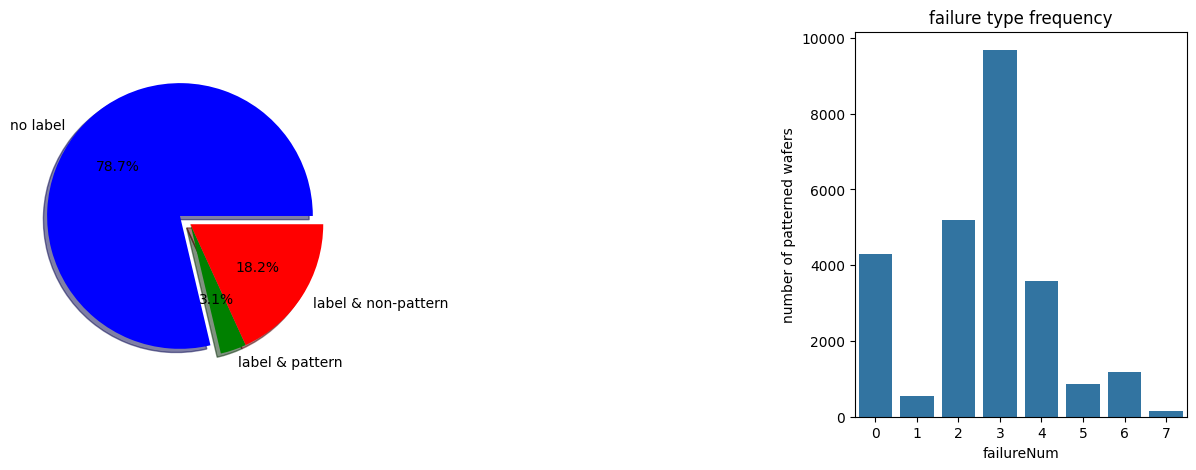

In [15]:
fig,ax = plt.subplots(1,2, figsize = (15,5))
colors = ['blue', 'green', 'red']
num_wafers=[len(df['waferMap'])-df_withlabel.shape[0], df_withpattern.shape[0], df_nonpattern.shape[0]]
labels = ['no label', 'label & pattern', 'label & non-pattern']
ax[0].pie(num_wafers, explode=(0.1,0,0), labels = labels, colors = colors, autopct = '%1.1f%%', shadow=True)
sns.countplot(x='failureNum', data=df_withpattern, ax=ax[1])
ax[1].set_title("failure type frequency")
ax[1].set_ylabel("number of patterned wafers")
plt.subplots_adjust(wspace = 1.5)
plt.show()

In [16]:
# Wafer dimension distribution

#max(df.waferMapDim), min(df.waferMapDim)
uni_waferDim=np.unique(df.waferMapDim, return_counts=True)
#uni_waferDim[0].shape[0]
df['waferMapDim'].value_counts(normalize = True)

waferMapDim
(32, 29)    0.133941
(25, 27)    0.078973
(49, 39)    0.048460
(26, 26)    0.037067
(30, 34)    0.036370
              ...   
(6, 21)     0.000001
(15, 3)     0.000001
(21, 17)    0.000001
(27, 15)    0.000001
(18, 44)    0.000001
Name: proportion, Length: 632, dtype: float64

The dimension of wafer map, or the image size are not always the same. We see that there are 632 different size for our wafer map. There is a variety of different wafer map dimensions, and they are not all perfectly circular.


---
Kích thước của bản đồ wafer, hay kích thước hình ảnh, không phải lúc nào cũng giống nhau. Chúng ta thấy rằng có 632 kích thước khác nhau cho bản đồ wafer của chúng ta. Có nhiều kích thước bản đồ wafer khác nhau, và chúng không phải tất cả đều là hình tròn hoàn hảo.


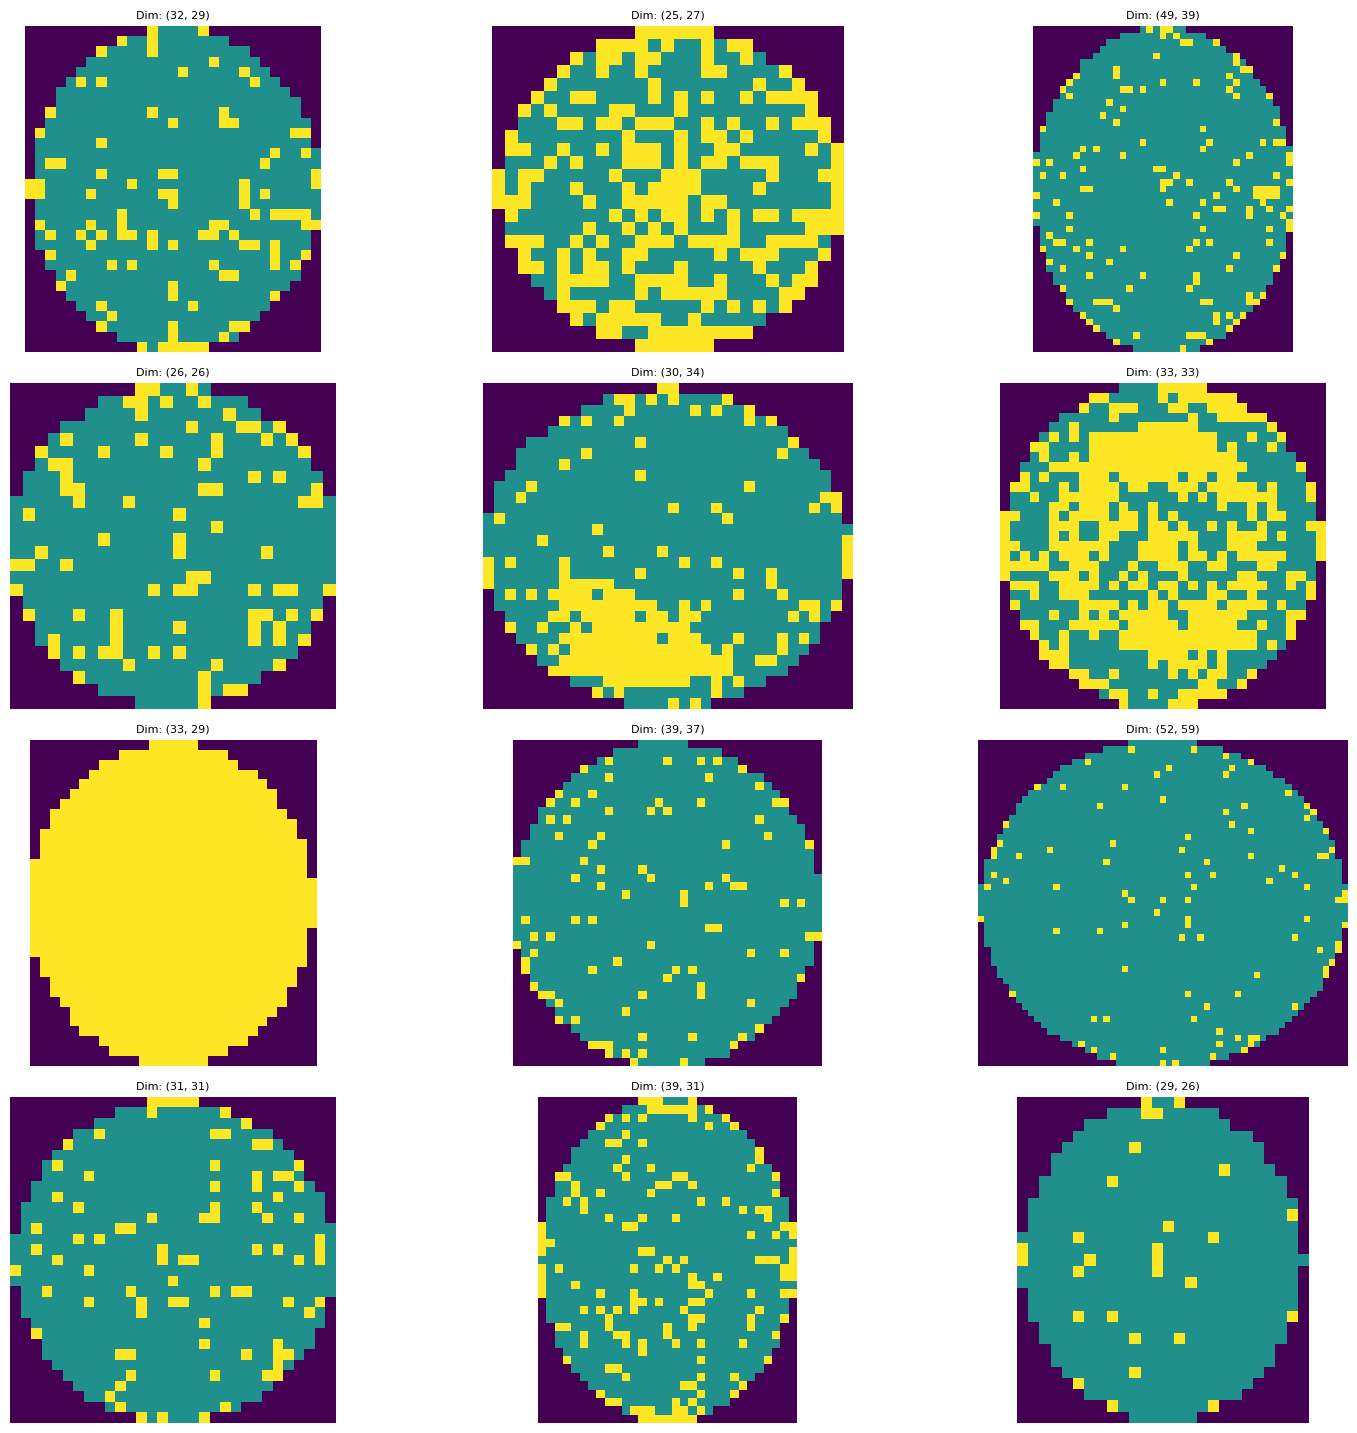

In [17]:
unique_dims = df['waferMapDim'].value_counts().index.tolist()

# Select up to 10 unique dimensions to plot
dims_to_plot = unique_dims[:12]

plt.figure(figsize=(15, len(dims_to_plot) * 1.5))
for i, dim in enumerate(dims_to_plot):
    # Get the first wafer map for this dimension
    wafer_map = df[df['waferMapDim'] == dim]['waferMap'].iloc[0]

    ax = plt.subplot(len(dims_to_plot) // 3 + 1, 3, i + 1)
    ax.imshow(wafer_map)
    ax.set_title(f'Dim: {dim}', fontsize=8)
    ax.axis('off')
plt.tight_layout()
plt.show()

**Image pre-processing**

Different image size --> image resizing

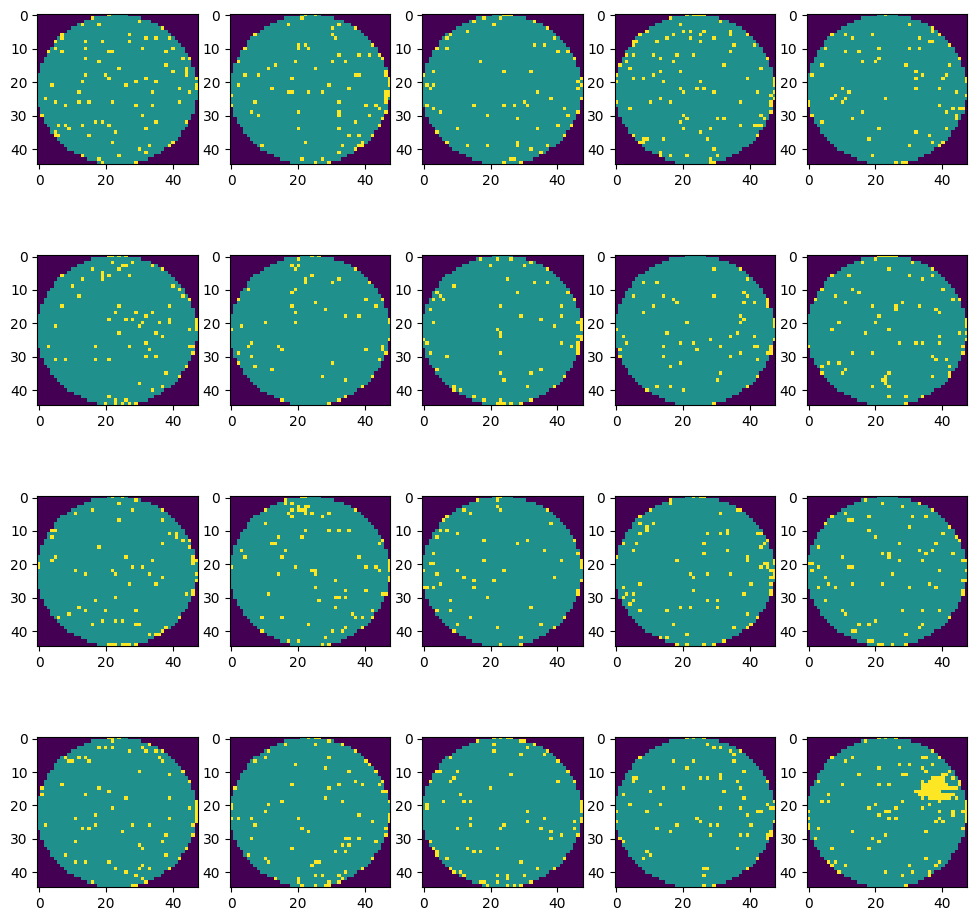

In [18]:
plt.figure(figsize=(12,12))
for i in range(20):
    ax = plt.subplot(4, 5, i+1)
    ax.imshow(df["waferMap"][i])